In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("credit_risk_dataset.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

Dataset shape: (32581, 12)

First five rows:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
# Check column names
print("Column names:")
print(df.columns.tolist())

# Check data types and non-null counts
print("\nDataset information:")
df.info()

Column names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   

In [3]:
# Count missing values in each column
missing_counts = df.isnull().sum()

# Calculate missing-value percentage
missing_percent = (missing_counts / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing Percentage": missing_percent.round(2)
})

# Display only columns with missing values
display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing Percentage
person_emp_length,895,2.75
loan_int_rate,3116,9.56


In [4]:
# Count exact duplicate rows
duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

# Display the duplicate records for inspection
display(df[df.duplicated(keep=False)].head(10))

Exact duplicate rows: 165


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
14,23,115000,RENT,2.0,EDUCATION,A,35000,7.90,0,0.30,N,4
238,22,183000,MORTGAGE,3.0,EDUCATION,A,1000,NaN,0,0.01,N,2
252,24,85000,RENT,5.0,MEDICAL,B,25000,10.62,0,0.29,N,4
591,26,20000,MORTGAGE,5.0,MEDICAL,A,4800,5.99,0,0.24,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
817,22,22000,OWN,1.0,DEBTCONSOLIDATION,D,8500,15.05,0,0.39,N,4
920,26,50000,RENT,10.0,PERSONAL,B,18950,NaN,1,0.38,N,3
1094,22,24449,OWN,2.0,VENTURE,B,1800,11.89,0,0.07,N,4
1142,25,60000,RENT,3.0,PERSONAL,A,17000,6.91,0,0.28,N,2
1453,23,20400,RENT,2.0,MEDICAL,A,1200,7.90,0,0.06,N,2


In [5]:
# Summary statistics for numerical columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [6]:
# Inspect ages above 100
print("Ages above 100:")
display(df[df["person_age"] > 100])

# Inspect employment lengths above 60
print("Employment lengths above 60:")
display(df[df["person_emp_length"] > 60])

# Inspect income above 1,000,000
print("Income above 1,000,000:")
display(df[df["person_income"] > 1_000_000])

Ages above 100:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


Employment lengths above 60:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


Income above 1,000,000:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
17833,32,1200000,MORTGAGE,1.0,VENTURE,A,12000,7.51,0,0.01,N,8
29119,36,1200000,OWN,16.0,MEDICAL,A,10000,6.54,0,0.01,N,11
29120,40,1200000,MORTGAGE,1.0,MEDICAL,A,10000,NaN,0,0.01,N,16
30049,42,2039784,RENT,0.0,VENTURE,C,8450,12.29,0,0.00,Y,15
31922,47,1362000,MORTGAGE,9.0,VENTURE,A,6600,7.74,0,0.00,N,17
31924,44,1440000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,6400,7.40,0,0.00,N,15
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25
32497,63,1782000,RENT,13.0,EDUCATION,C,12025,14.27,0,0.01,N,30
32546,60,1900000,MORTGAGE,5.0,PERSONAL,A,1500,NaN,0,0.00,N,21


In [7]:
# Find employment lengths greater than borrower age
age_employment_issues = df[
    df["person_emp_length"] > df["person_age"]
]

print("Records where employment length exceeds age:",
      len(age_employment_issues))

display(age_employment_issues[
    ["person_age", "person_emp_length", "person_income"]
].head(10))

Records where employment length exceeds age: 2


,person_age,person_emp_length,person_income
0,22,123.0,59000
210,21,123.0,192000


In [8]:
# Inspect unique values in categorical columns
categorical_columns = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


person_home_ownership:
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

loan_intent:
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

loan_grade:
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

cb_person_default_on_file:
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


In [9]:
print("Loan status counts:")
print(df["loan_status"].value_counts(dropna=False))

print("\nLoan status percentages:")
print(
    (df["loan_status"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Loan status counts:
loan_status
0    25473
1     7108
Name: count, dtype: int64

Loan status percentages:
loan_status
0    78.18
1    21.82
Name: proportion, dtype: float64


In [10]:
# Preserve the original data and create a working copy
df_raw = df.copy()
df_clean = df.copy()

print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (32581, 12)
Working dataset shape: (32581, 12)


In [11]:
# Check missing interest rates by loan grade

rate_missing_by_grade = df_raw.groupby("loan_grade").agg(
    Total_Records=("loan_int_rate", "size"),
    Missing_Rates=("loan_int_rate", lambda x: x.isna().sum()),
    Average_Rate=("loan_int_rate", "mean")
)

rate_missing_by_grade["Missing_Percentage"] = (
    rate_missing_by_grade["Missing_Rates"]
    / rate_missing_by_grade["Total_Records"] * 100
).round(2)

display(rate_missing_by_grade)

,Total_Records,Missing_Rates,Average_Rate,Missing_Percentage
loan_grade,,,,
A,10777,1003,7.327651,9.31
B,10451,1056,10.995555,10.10
C,6458,630,13.463542,9.76
D,3626,312,15.361448,8.60
E,964,83,17.009455,8.61
F,241,27,18.609159,11.20
G,64,5,20.251525,7.81


In [12]:
# Calculate median interest rate for each loan grade
median_rate_by_grade = df_raw.groupby("loan_grade")["loan_int_rate"].median()

print("Median interest rate by grade:")
display(median_rate_by_grade)

Median interest rate by grade:


loan_grade
A     7.490
B    10.990
C    13.480
D    15.310
E    16.820
F    18.535
G    20.160
Name: loan_int_rate, dtype: float64

In [13]:
# Flag records whose interest rates were originally missing
df_clean["interest_rate_was_missing"] = (
    df_clean["loan_int_rate"].isna().astype(int)
)

# Fill missing interest rates using the median for each loan grade
df_clean["loan_int_rate"] = (
    df_clean.groupby("loan_grade")["loan_int_rate"]
    .transform(lambda x: x.fillna(x.median()))
)

# Verify the result
print("Missing interest rates before cleaning:", df_raw["loan_int_rate"].isna().sum())
print("Missing interest rates after cleaning:", df_clean["loan_int_rate"].isna().sum())
print("\nOriginal missing-value flag:")
print(df_clean["interest_rate_was_missing"].value_counts())

Missing interest rates before cleaning: 3116
Missing interest rates after cleaning: 0

Original missing-value flag:
interest_rate_was_missing
0    29465
1     3116
Name: count, dtype: int64


In [14]:
# Remember which employment lengths were originally missing
df_clean["employment_length_was_missing"] = (
    df_clean["person_emp_length"].isna().astype(int)
)

# Calculate the median from the original data
employment_median = df_raw["person_emp_length"].median()

print("Median employment length:", employment_median)

# Fill missing values in the working copy
df_clean["person_emp_length"] = (
    df_clean["person_emp_length"].fillna(employment_median)
)

# Verify the result
print(
    "Missing employment lengths after cleaning:",
    df_clean["person_emp_length"].isna().sum()
)

Median employment length: 4.0
Missing employment lengths after cleaning: 0


In [15]:
# Replace invalid values with missing values
df_clean.loc[df_clean["person_age"] > 100, "person_age"] = np.nan
df_clean.loc[df_clean["person_emp_length"] > 60, "person_emp_length"] = np.nan

# Fill using medians
df_clean["person_age"] = df_clean["person_age"].fillna(df_clean["person_age"].median())
df_clean["person_emp_length"] = df_clean["person_emp_length"].fillna(df_clean["person_emp_length"].median())

print("Invalid values handled.")
print("Rows retained:", len(df_clean))

Invalid values handled.
Rows retained: 32581


In [16]:
df_clean = df_clean.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df_clean))

Rows after removing duplicates: 32416


In [17]:
print("Remaining missing values:")
print(df_clean.isnull().sum().sum())

print("Dataset shape:", df_clean.shape)

Remaining missing values:
0
Dataset shape: (32416, 14)


In [18]:
df_clean["loan_to_income_ratio"] = (
    df_clean["loan_amnt"] / df_clean["person_income"]
).round(2)

print(df_clean[[
    "person_income", "loan_amnt", "loan_to_income_ratio"
]].head())

   person_income  loan_amnt  loan_to_income_ratio
0          59000      35000                  0.59
1           9600       1000                  0.10
2           9600       5500                  0.57
3          65500      35000                  0.53
4          54400      35000                  0.64


In [19]:
print(df_clean[[
    "loan_percent_income",
    "loan_to_income_ratio"
]].head(10))

   loan_percent_income  loan_to_income_ratio
0                 0.59                  0.59
1                 0.10                  0.10
2                 0.57                  0.57
3                 0.53                  0.53
4                 0.55                  0.64
5                 0.25                  0.25
6                 0.45                  0.45
7                 0.44                  0.44
8                 0.42                  0.42
9                 0.16                  0.16


In [20]:
df_clean.drop(columns=["loan_to_income_ratio"], inplace=True)

print("Redundant column removed.")
print("Dataset shape:", df_clean.shape)

Redundant column removed.
Dataset shape: (32416, 14)


In [21]:
df_clean["loan_burden"] = pd.cut(
    df_clean["loan_percent_income"],
    bins=[-float("inf"), 0.10, 0.30, float("inf")],
    labels=["Low", "Medium", "High"]
)

print("Loan burden feature created.")

Loan burden feature created.


In [22]:
df_clean.groupby("loan_burden")["loan_status"].mean().mul(100).round(2)

loan_burden
Low       11.75
Medium    17.47
High      70.44
Name: loan_status, dtype: float64

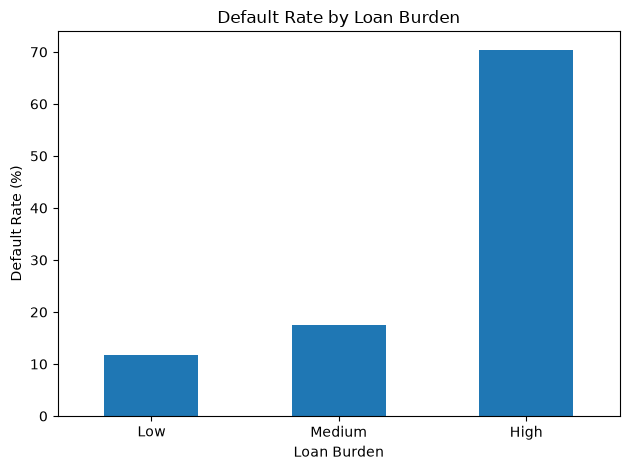

In [23]:

rates = df_clean.groupby("loan_burden")["loan_status"].mean() * 100

rates.plot(kind="bar", title="Default Rate by Loan Burden",
           ylabel="Default Rate (%)", xlabel="Loan Burden")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [24]:
grade_rates = df_clean.groupby("loan_grade")["loan_status"].mean() * 100
print(grade_rates.round(2))

loan_grade
A     9.96
B    16.32
C    20.75
D    59.06
E    64.49
F    70.54
G    98.44
Name: loan_status, dtype: float64


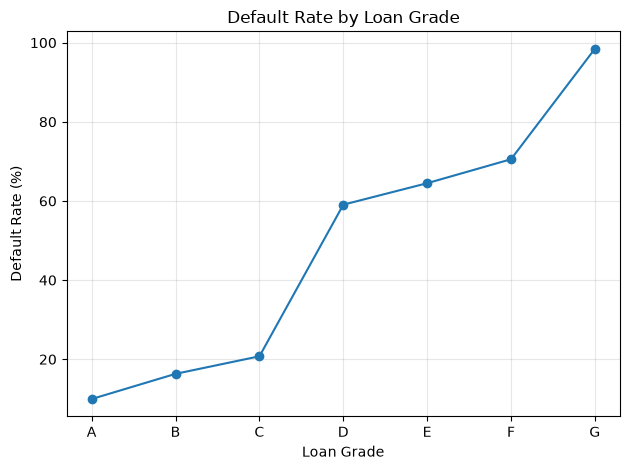

In [25]:

grade_rates.plot(
    kind="line", marker="o",
    title="Default Rate by Loan Grade",
    ylabel="Default Rate (%)",
    xlabel="Loan Grade"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [26]:

purpose_rates = (
    df_clean.groupby("loan_intent")["loan_status"].mean() * 100
).round(2)

print(purpose_rates.sort_values(ascending=False))


loan_intent
DEBTCONSOLIDATION    28.68
MEDICAL              26.76
HOMEIMPROVEMENT      26.15
PERSONAL             19.90
EDUCATION            17.25
VENTURE              14.85
Name: loan_status, dtype: float64


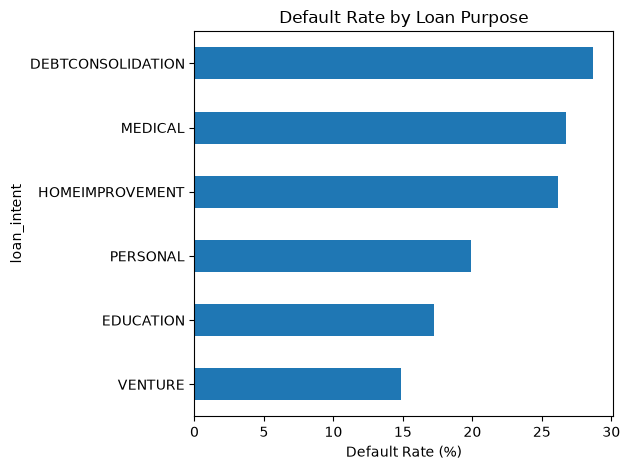

In [35]:

purpose_rates.sort_values().plot(kind="barh",
    title="Default Rate by Loan Purpose",
    xlabel="Default Rate (%)")

plt.tight_layout()
plt.show()


In [28]:

home_rates = df_clean.groupby("person_home_ownership")["loan_status"].mean() * 100

print(home_rates.round(2))


person_home_ownership
MORTGAGE    12.62
OTHER       31.13
OWN          7.49
RENT        31.61
Name: loan_status, dtype: float64


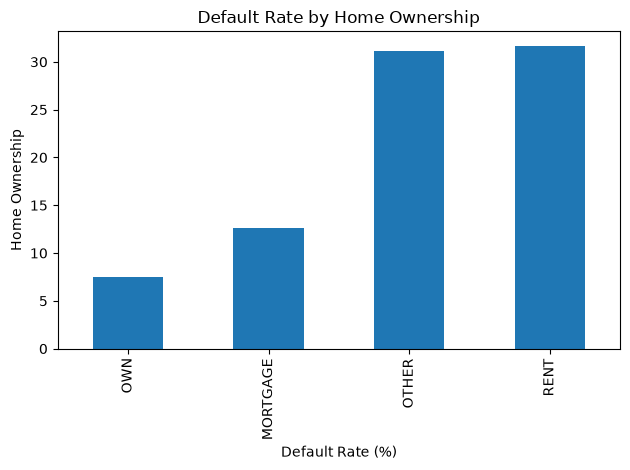

In [33]:

home_rates.sort_values().plot(
    kind="bar",
    title="Default Rate by Home Ownership",
    xlabel="Default Rate (%)",
    ylabel="Home Ownership"
)

plt.tight_layout()
plt.show()


In [36]:

df_clean.groupby("loan_status")["loan_int_rate"].mean().round(2)


loan_status
0    10.45
1    13.05
Name: loan_int_rate, dtype: float64

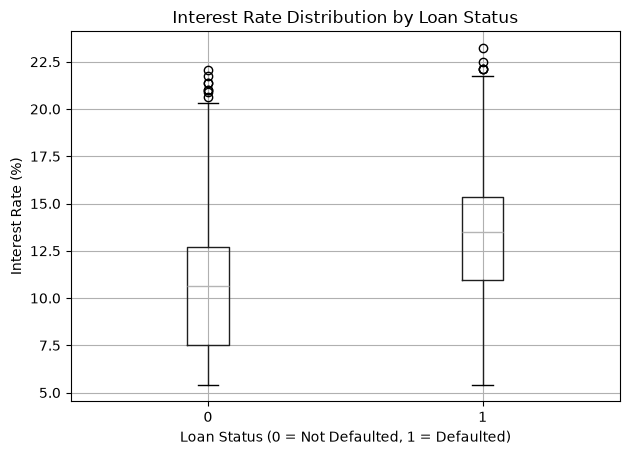

In [42]:

df_clean.boxplot(column="loan_int_rate", by="loan_status")

plt.title("Interest Rate Distribution by Loan Status")
plt.suptitle("")
plt.xlabel("Loan Status (0 = Not Defaulted, 1 = Defaulted)")
plt.ylabel("Interest Rate (%)")
plt.tight_layout()
plt.show()


In [48]:
print("Highest loan amount:", df_clean["loan_amnt"].max())
print("Lowest loan amount:", df_clean["loan_amnt"].min())

correlation = df_clean["person_income"].corr(df_clean["loan_amnt"])
print("Income vs Loan Amount Correlation:", round(correlation, 2))

Highest loan amount: 35000
Lowest loan amount: 500
Income vs Loan Amount Correlation: 0.27


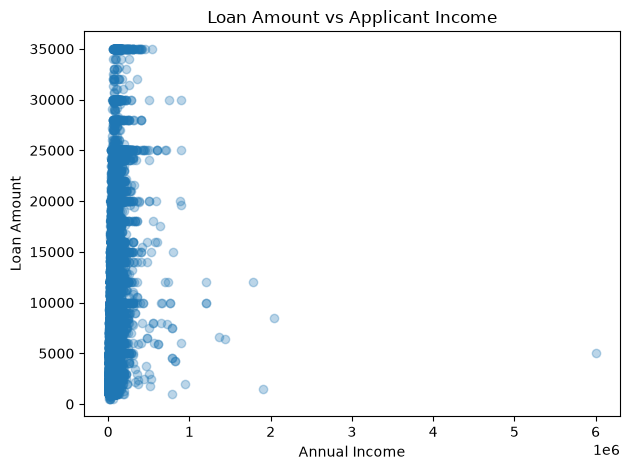

In [43]:

plt.scatter(df_clean["person_income"], df_clean["loan_amnt"],
            alpha=0.3)

plt.title("Loan Amount vs Applicant Income")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()


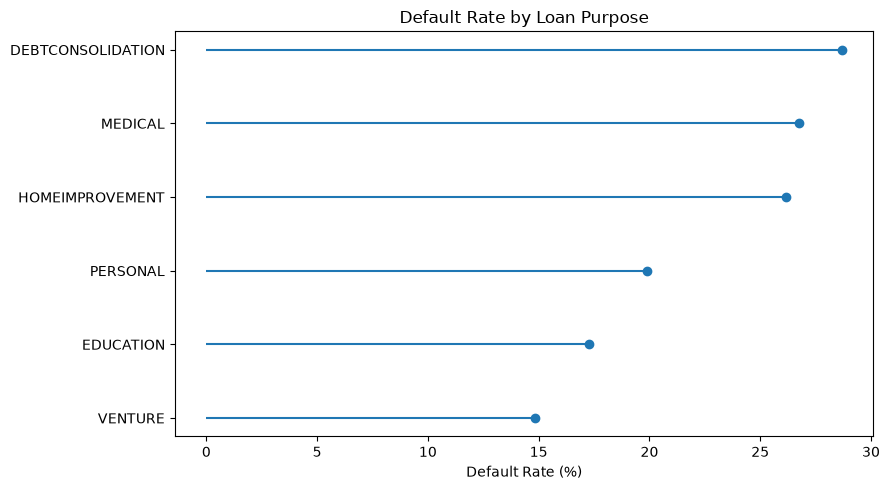

Highest default rate: DEBTCONSOLIDATION 28.68 %
Lowest default rate: VENTURE 14.85 %


In [44]:

rates = df_clean.groupby("loan_intent")["loan_status"].mean() * 100
rates = rates.sort_values()

plt.figure(figsize=(9, 5))
plt.hlines(range(len(rates)), 0, rates.values)
plt.scatter(rates.values, range(len(rates)))

plt.yticks(range(len(rates)), rates.index)
plt.xlabel("Default Rate (%)")
plt.title("Default Rate by Loan Purpose")
plt.tight_layout()
plt.show()

print("Highest default rate:", rates.idxmax(), round(rates.max(), 2), "%")
print("Lowest default rate:", rates.idxmin(), round(rates.min(), 2), "%")


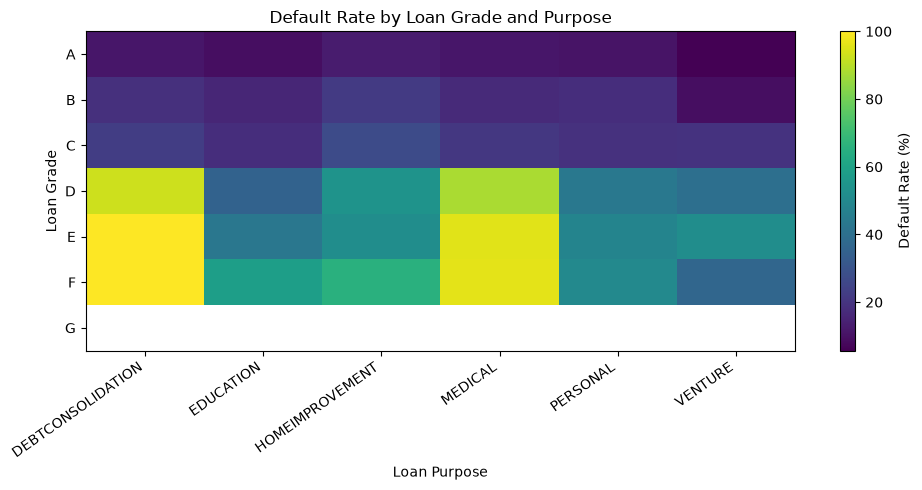

Highest default rate (minimum 30 loans): ('E', 'DEBTCONSOLIDATION')
Default rate: 100.0 %


In [46]:

import numpy as np
import matplotlib.pyplot as plt

groups = df_clean.groupby(
    ["loan_grade", "loan_intent"]
)["loan_status"]

rates = groups.mean().unstack() * 100
counts = groups.count().unstack()

# Hide combinations with fewer than 30 loans
rates = rates.where(counts >= 30)

plt.figure(figsize=(10, 5))
plt.imshow(np.ma.masked_invalid(rates.values), aspect="auto")
plt.colorbar(label="Default Rate (%)")

plt.xticks(range(len(rates.columns)), rates.columns,
           rotation=35, ha="right")
plt.yticks(range(len(rates.index)), rates.index)
plt.xlabel("Loan Purpose")
plt.ylabel("Loan Grade")
plt.title("Default Rate by Loan Grade and Purpose")
plt.tight_layout()
plt.show()

highest = rates.stack().idxmax()
print("Highest default rate (minimum 30 loans):", highest)
print("Default rate:", round(rates.stack().max(), 2), "%")
